# Assignment 4.2: XGBoost and the ML Lifecycle
AAI-501 | Module 4

**Student:** Justin Nguyen  
**Program:** M.S. Applied Artificial Intelligence, University of San Diego

In [1]:
from sklearn.datasets import load_breast_cancer
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
breast_cancer = load_breast_cancer(as_frame=True)

num_rows = breast_cancer.data.shape[0]
num_cols = breast_cancer.data.shape[1]

print(breast_cancer.data.head())
print(num_rows)
print(num_cols)

   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst perimeter  \
0           

---
## Part 1: Dataset Overview
Answer each question below.

### 1) What the dataset contains
**Question:** What the dataset contains

**Answer:**

The dataset measures a digitized image of a fine needle aspirate of breast mass. There are 30 features (10 real-valued features and the mean, standard error, and largest of the three largest values for each feature) and 569 rows.

### 2) Where it originated
**Question:** Where it originated

**Answer:**

This dataset was introduced in a paper titled 'Nuclear feature extraction for breast tumor diagnosis' by W. Street, W. Wolberg, O. Mangasarian in 1993.

### 3) The classification problem
**Question:** The classification problem being solved

**Answer:**

The problem being solved is whether a tumor is benign or malignant.

### 4) Why this problem matters
**Question:** Why solving this problem is important

**Answer:**

This creates a system that can give a faster and more consistent screening so that doctors can see more patients efficiently.

---
## Part 2: EDA

In [3]:
features = breast_cancer.data.columns
print(features)

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension'],
      dtype='str')


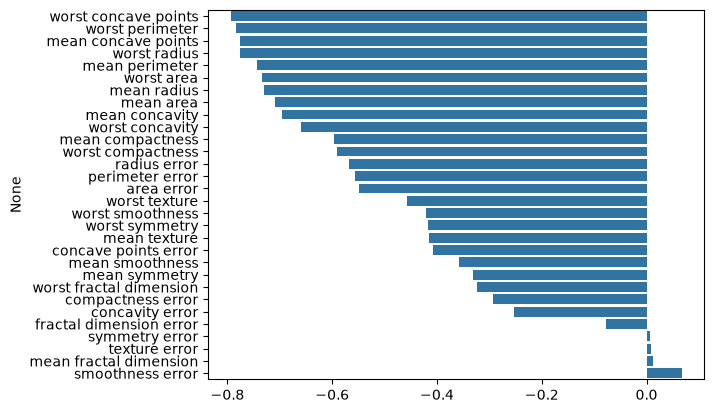

In [4]:
corr = breast_cancer.data.corrwith(breast_cancer.target).sort_values()
sns.barplot(x=corr.values, y=corr.index)
plt.show()

### 2.1 Shape, types, missing values, duplicates

In [5]:
df = breast_cancer.frame  # features + 'target'
print(df.shape)
print(df.dtypes.value_counts())
print('missing values:', df.isnull().sum().sum())
print('duplicate rows:', df.duplicated().sum())

(569, 31)
float64    30
int64       1
Name: count, dtype: int64
missing values: 0
duplicate rows: 0


### 2.2 Class balance
`target`: 0 = malignant, 1 = benign

malignant    212
benign       357
Name: count, dtype: int64
malignant    0.373
benign       0.627
Name: count, dtype: float64


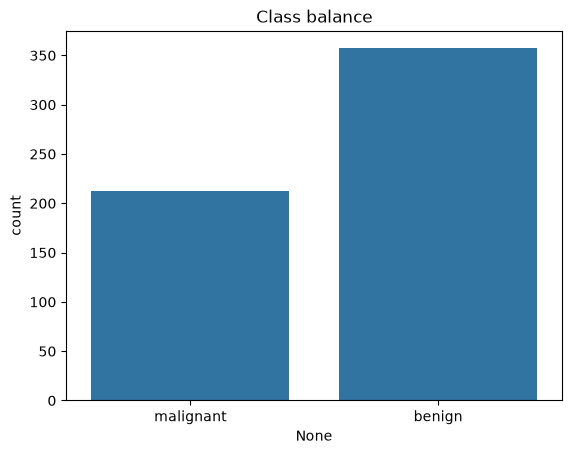

In [6]:
counts = df['target'].value_counts().sort_index()
counts.index = breast_cancer.target_names
print(counts)
print((counts / len(df)).round(3))
sns.barplot(x=counts.index, y=counts.values)
plt.ylabel('count')
plt.title('Class balance')
plt.show()

### 2.3 Summary statistics

In [7]:
print(breast_cancer.data.describe().T[['mean', 'std', 'min', 'max']].round(3))

                            mean      std      min       max
mean radius               14.127    3.524    6.981    28.110
mean texture              19.290    4.301    9.710    39.280
mean perimeter            91.969   24.299   43.790   188.500
mean area                654.889  351.914  143.500  2501.000
mean smoothness            0.096    0.014    0.053     0.163
mean compactness           0.104    0.053    0.019     0.345
mean concavity             0.089    0.080    0.000     0.427
mean concave points        0.049    0.039    0.000     0.201
mean symmetry              0.181    0.027    0.106     0.304
mean fractal dimension     0.063    0.007    0.050     0.097
radius error               0.405    0.277    0.112     2.873
texture error              1.217    0.552    0.360     4.885
perimeter error            2.866    2.022    0.757    21.980
area error                40.337   45.491    6.802   542.200
smoothness error           0.007    0.003    0.002     0.031
compactness error       

### 2.4 Distributions by class
Four features most tied to the target (from the bar plot above).

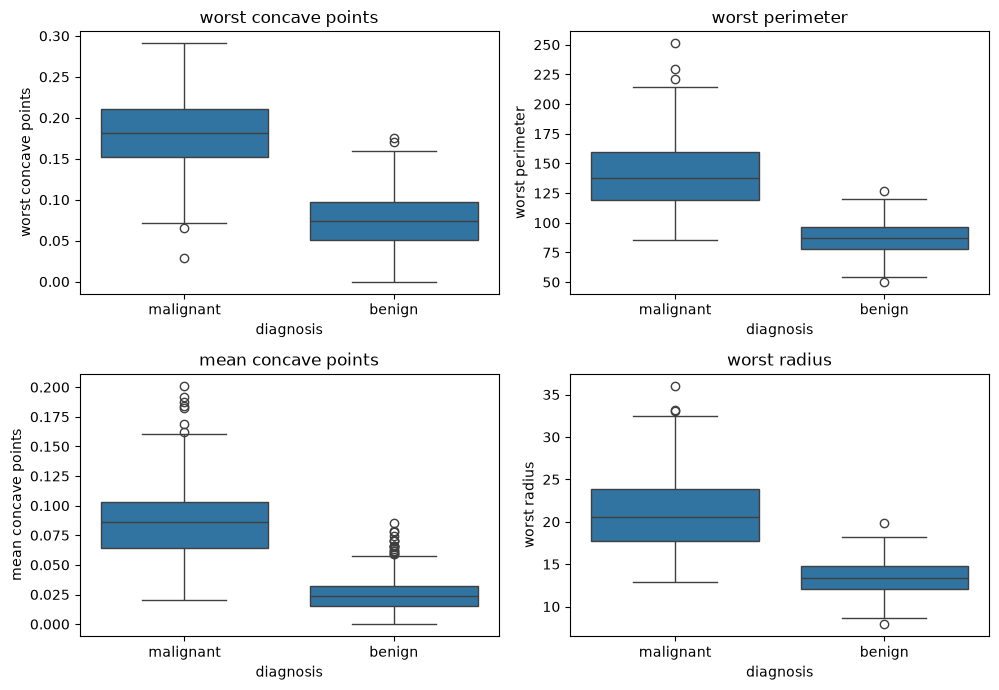

In [8]:
top = ['worst concave points', 'worst perimeter', 'mean concave points', 'worst radius']
labeled = df.copy()
labeled['diagnosis'] = labeled['target'].map(dict(enumerate(breast_cancer.target_names)))
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, col in zip(axes.ravel(), top):
    sns.boxplot(data=labeled, x='diagnosis', y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### 2.5 Correlation between features

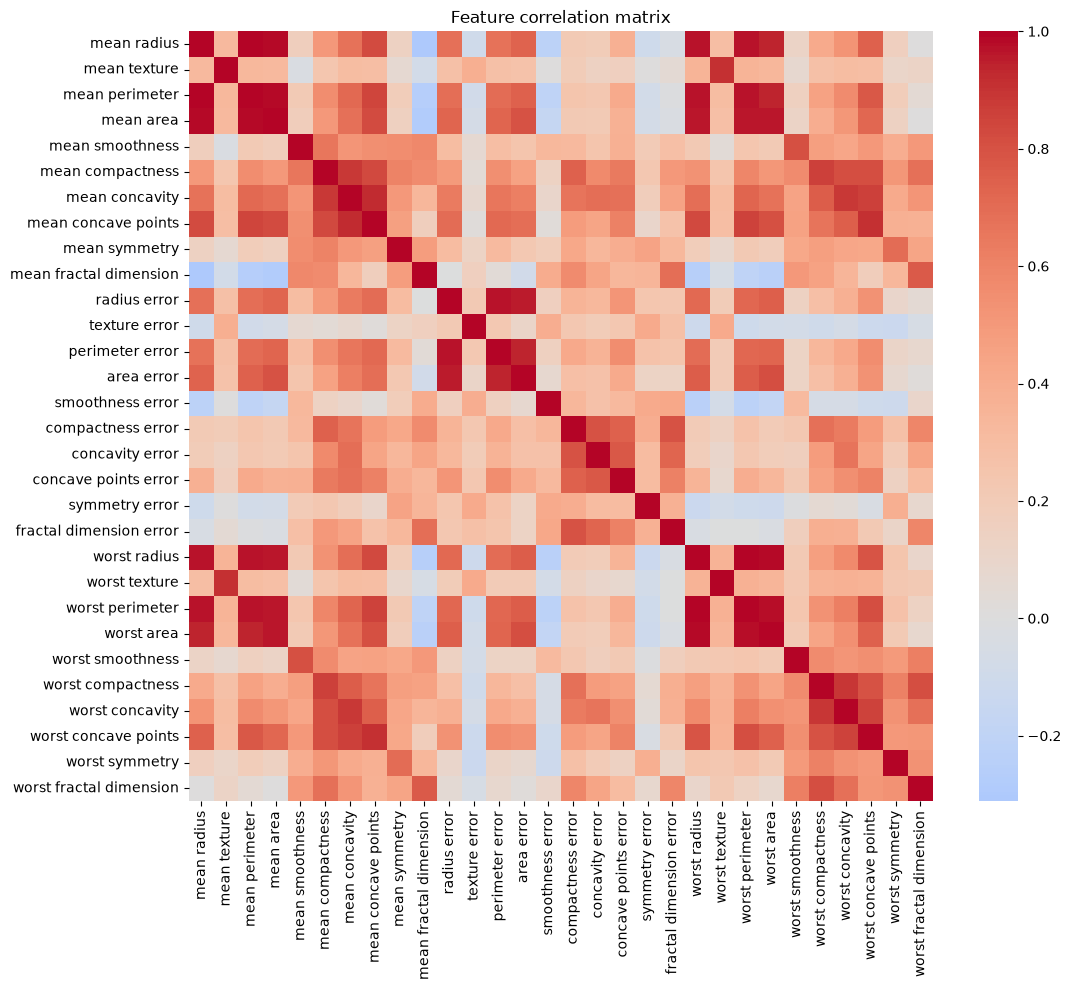

21 pairs with |r| > 0.9
mean radius      mean perimeter     0.998
worst radius     worst perimeter    0.994
mean radius      mean area          0.987
mean perimeter   mean area          0.987
worst radius     worst area         0.984
worst perimeter  worst area         0.978
radius error     perimeter error    0.973
mean perimeter   worst perimeter    0.970
mean radius      worst radius       0.970
mean perimeter   worst radius       0.969
dtype: float64


In [9]:
corr_matrix = breast_cancer.data.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0)
plt.title('Feature correlation matrix')
plt.show()

# strongly correlated pairs (|r| > 0.9), each pair listed once
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))
pairs = upper.stack()
pairs = pairs[pairs.abs() > 0.9].sort_values(ascending=False)
print(len(pairs), 'pairs with |r| > 0.9')
print(pairs.head(10).round(3))

### 2.6 Pairplot of the top features

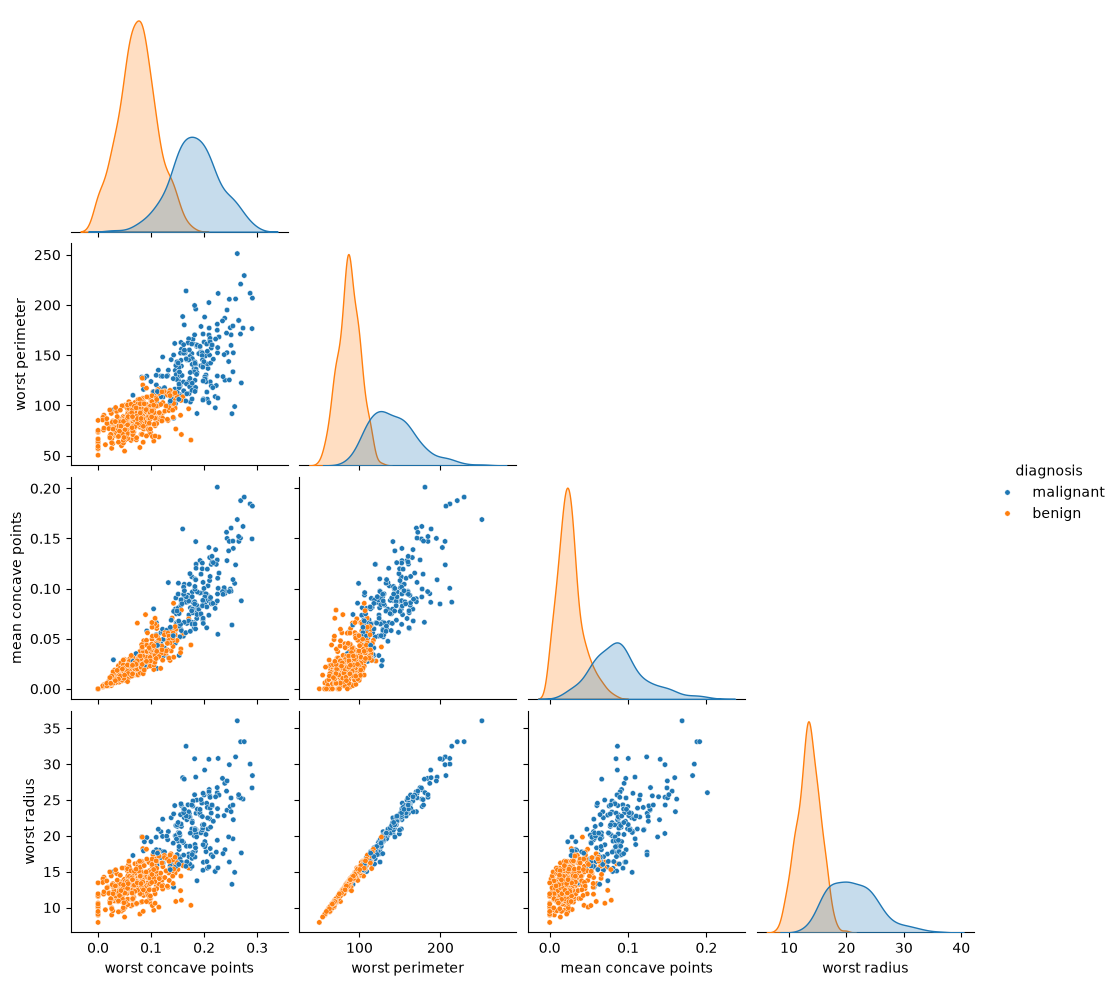

In [10]:
sns.pairplot(labeled, vars=top, hue='diagnosis', corner=True, plot_kws={'s': 15})
plt.show()

### EDA Summary
The dataset has 569 tumors and 30 numeric features with no missing values or duplicates, so no cleaning was needed. There are 357 benign and 212 malignant cases (62.7% vs 37.3%), which is a mild class imbalance. The box plots and the correlation bar plot show that the size and shape features separate the classes best, led by worst concave points, worst perimeter, mean concave points and worst radius (r around -0.78); since benign is coded as 1, higher values of these point to malignant. Features like smoothness error, mean fractal dimension, texture error and symmetry error have almost no correlation with the target. The heatmap shows 21 feature pairs with |r| > 0.9, such as mean radius and mean perimeter (0.998), because radius, perimeter and area all measure tumor size. **Modeling considerations:** because of the class imbalance I will use a stratified train/test split and judge the model on recall and F1 for the malignant class, not accuracy alone; the features also sit on very different scales (mean area reaches 2501 while mean smoothness is about 0.1), which would matter for a linear model but not for tree-based XGBoost.

---
## Part 3: Hyperparameter Selection

Max depth and learning rate since this is a small dataset. Since the dataset is small, risk of overfitting is higher so we keep the max depth shallow and the steps small.

---
## Part 4: Initial Model Training


In [13]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import recall_score, f1_score

In [20]:
model = xgb.XGBClassifier(max_depth=3, learning_rate=0.03)
x_train, x_test, y_train, y_test = train_test_split(breast_cancer.data, breast_cancer.target, test_size=0.3, random_state=4)
model.fit(x_train, y_train)
y_test_pred = model.predict(x_test)
print("Recall:", recall_score(y_test, y_test_pred, pos_label=0))
print("F1 Score:", f1_score(y_test, y_test_pred, pos_label=0))



Recall: 0.9259259259259259
F1 Score: 0.9090909090909091


I chose recall because there are higher stakes for missing a malignant tumor and F1 score to balance recall with precisions to prevent the model from just flagging every tumor as malignant.

---
## Part 5: Hyperparameter Tuning

In [21]:
from sklearn.model_selection import GridSearchCV

In [22]:
max_depths = [2, 3, 4, 5]
learning_rates = [0.3, 0.03, 0.003]
param_grid = {
    'max_depth': max_depths,
    'learning_rate': learning_rates
}
grid_search = GridSearchCV(estimator=xgb.XGBClassifier(), param_grid=param_grid, scoring='recall', cv=3)
grid_search.fit(x_train, y_train)
print("Best parameters:", grid_search.best_params_)
print("Best recall score:", grid_search.best_score_)

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(x_test)
print("Recall with best model:", recall_score(y_test, y_pred_best, pos_label=0))
print("F1 Score with best model:", f1_score(y_test, y_pred_best, pos_label=0))



Best parameters: {'learning_rate': 0.3, 'max_depth': 2}
Best recall score: 0.9833333333333334
Recall with best model: 0.9259259259259259
F1 Score with best model: 0.9090909090909091


The best hyperparameter combination is a learning rate of 0.3 and a max depth of 2. The model with tuned parameters performs exactly the same as my model. I'll just use my model as the final model.

---
## Part 6: Feature Importance and Interpretation

In [ ]:
feature_importances = model.feature_importances_
sorted_features = sorted(zip(breast_cancer.feature_names, feature_importances), key=lambda x: x[1], reverse=True)
print("\nFeatures sorted by importance:")
for feature, importance in sorted_features:
    print(f"{feature}: {importance}")


Features sorted by importance:
worst perimeter: 0.522817075252533
worst area: 0.10327010601758957
worst radius: 0.05378871038556099
mean concave points: 0.05354442447423935
mean radius: 0.0420132577419281
worst concave points: 0.03944552317261696
worst smoothness: 0.03642638400197029
mean texture: 0.02017948217689991
worst texture: 0.01835150644183159
worst symmetry: 0.015522058121860027
worst concavity: 0.015301002189517021
worst compactness: 0.013538654893636703
mean fractal dimension: 0.013145877048373222
perimeter error: 0.012587633915245533
area error: 0.011630567722022533
radius error: 0.010030032135546207
smoothness error: 0.009896958246827126
fractal dimension error: 0.005697543732821941
symmetry error: 0.002813199069350958
mean perimeter: 0.0
mean area: 0.0
mean smoothness: 0.0
mean compactness: 0.0
mean concavity: 0.0
mean symmetry: 0.0
texture error: 0.0
compactness error: 0.0
concavity error: 0.0
concave points error: 0.0
worst fractal dimension: 0.0


Worst perimeter is the strongest feature with an importance of 0.52 with the next strongest being worst area with a 0.10 importance. In a medical context, doctors can check the model easier to build trust for instance, if the top features aren't what they would check for malignance in a tumor than they know the model is not trustworthy.

*Disclaimer: AI was used to help with the coding for this assignment.*